# 16 · Break the training loop on purpose: five fault signatures

In [1]:
import mujoco, mujoco_menagerie as mm, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt

def make_dataset(n=10000, seed=0):
    model = mm.load("franka_emika_panda"); data = mujoco.MjData(model)
    rng = np.random.default_rng(seed)
    lo, hi = model.jnt_range[:7, 0], model.jnt_range[:7, 1]
    X, Y = np.zeros((n, 14), np.float32), np.zeros((n, 7), np.float32)
    for i in range(n):
        data.qpos[:7] = rng.uniform(lo, hi); data.qvel[:7] = rng.normal(0, 1.0, 7)
        mujoco.mj_forward(model, data)
        X[i] = np.r_[data.qpos[:7], data.qvel[:7]]; Y[i] = data.qfrc_bias[:7]
    return X, Y

def train(X, Y, fault=None, epochs=15, batch=64, clip=None, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    lr = {"big_lr": 1.0, "tiny_lr": 1e-8}.get(fault, 1e-3)
    Y = Y.copy()
    if fault == "bimodal_labels":
        Y[::2] += 3 * Y.std(0)
    mx, sx = X.mean(0), X.std(0)
    my, sy = Y.mean(0), Y.std(0)
    Xn = X * 50 if fault == "unnormalized_inputs" else (X - mx) / sx
    Xn, Yn = torch.tensor(Xn, dtype=torch.float32), torch.tensor((Y - my) / sy, dtype=torch.float32)
    model = nn.Sequential(nn.Linear(14, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 7))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for _ in range(epochs):
        perm = torch.randperm(len(Xn))
        for i in range(0, len(Xn), batch):
            idx = perm[i:i + batch]
            y = Yn[idx].clone()
            if fault == "action_outlier" and rng.random() < 0.05:
                y[0, 3] = 1e2
            loss = nn.functional.mse_loss(model(Xn[idx]), y)
            opt.zero_grad(); loss.backward()
            if clip:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            losses.append(loss.item() if np.isfinite(loss.item()) else np.nan)
    return np.array(losses)

def smooth(x, k=50):
    return np.convolve(np.nan_to_num(x, nan=1e8), np.ones(k) / k, mode="valid")

In [2]:
X, Y = make_dataset()
runs = {f: train(X, Y, fault=f) for f in [None, "big_lr", "tiny_lr", "unnormalized_inputs", "action_outlier", "bimodal_labels"]}

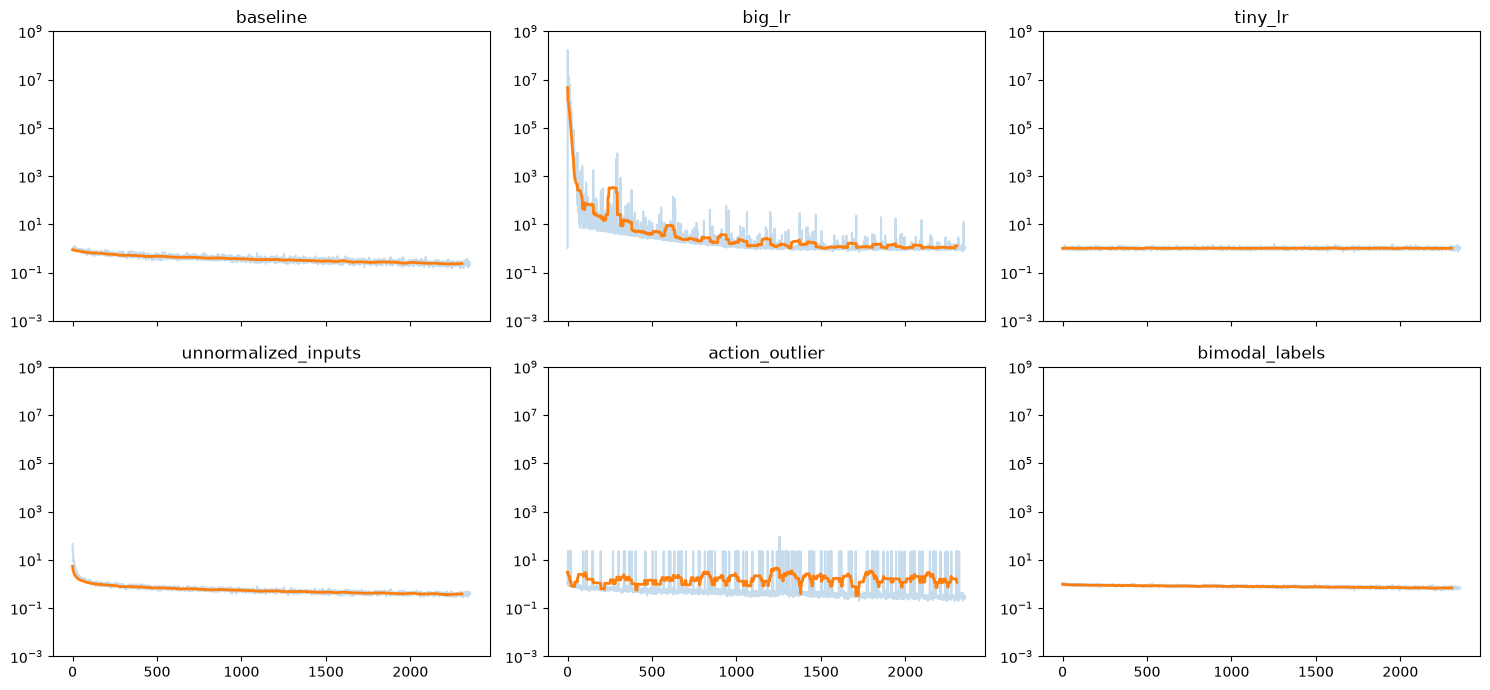

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for ax, (name, l) in zip(axes.flat, runs.items()):
    ax.semilogy(np.clip(l, 1e-4, 1e9), alpha=0.25); ax.semilogy(np.clip(smooth(l), 1e-4, 1e9), lw=2)
    ax.set_title(name or "baseline"); ax.set_ylim(1e-3, 1e9)
plt.tight_layout(); plt.show()

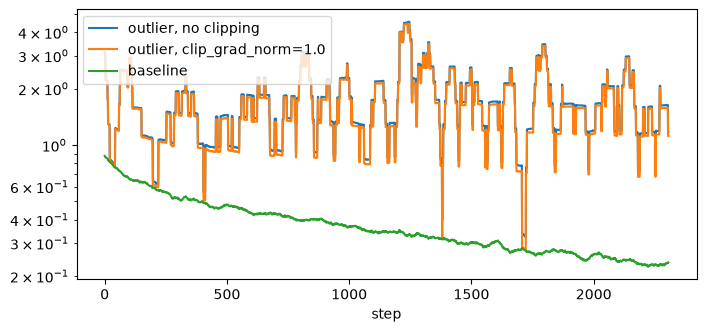

In [4]:
clipped = train(X, Y, fault="action_outlier", clip=1.0)
plt.figure(figsize=(8, 3.5))
plt.semilogy(smooth(runs["action_outlier"]), label="outlier, no clipping"); plt.semilogy(smooth(clipped), label="outlier, clip_grad_norm=1.0")
plt.semilogy(smooth(runs[None]), label="baseline"); plt.legend(); plt.xlabel("step"); plt.show()